# Hospital Readmission Prediction - Exploration & Modeling

**Goal:** predict whether a diabetic patient will be **readmitted to hospital within 30 days**
of discharge, using only information known *at discharge time*.

**Why it matters (business framing):** an avoidable 30-day readmission is expensive. The hospital
pays for the extra care, and under the CMS Hospital Readmissions Reduction Program (HRRP) it can
also face payment penalties. If we can flag high-risk patients before they leave, staff can act
early with follow-up calls, medication reviews, or a care plan.

**Dataset:** UCI *Diabetes 130-US hospitals (1999–2008)* — ~101,766 encounters, 50 columns.
Public data, no real patient identifiers.

**Notebook flow:**
1. Load the data
2. Missing values
3. Define the 30-day readmission target
4. Class balance
5. Exploratory analysis
6. Cleaning & feature prep
7. Model 3 classifiers with class-imbalance handling
8. Evaluation (ROC, confusion matrix, precision / recall)
9. Feature importance
10. Cost / ROI angle
11. Save processed data, figures, and best model


## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 60)

# Paths (relative to the notebooks/ folder)
RAW_DIR       = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
FIG_DIR       = Path("../reports/figures")
MODEL_DIR     = Path("../models")
for d in (PROCESSED_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 2. Load the data

Missing values in this dataset are stored as the string `"?"`, so we tell pandas to read them as `NaN`.

In [2]:
df = pd.read_csv(RAW_DIR / "diabetic_data.csv", na_values="?")
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 101,766  |  Columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# ID mapping file (admission type, discharge disposition, admission source)
ids_raw = (RAW_DIR / "IDS_mapping.csv").read_text().splitlines()
print("\n".join(ids_raw[:12]))      

admission_type_id,description
1,Emergency
2,Urgent
3,Elective
4,Newborn
5,Not Available
6,NULL
7,Trauma Center
8,Not Mapped
,
discharge_disposition_id,description
1,Discharged to home


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

## 3. Missing values

A few columns are mostly empty. `weight` is missing for ~97% of rows, and `payer_code` /
`medical_specialty` are missing for ~40-50%. We will drop the near-empty ones and keep the rest.

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "pct": missing_pct})

,missing,pct
weight,98569,96.9
max_glu_serum,96420,94.7
A1Cresult,84748,83.3
medical_specialty,49949,49.1
payer_code,40256,39.6
race,2273,2.2
diag_3,1423,1.4
diag_2,358,0.4
diag_1,21,0.0


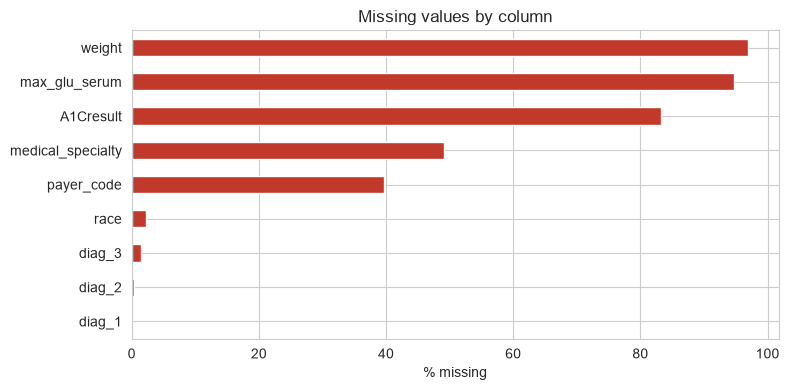

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
missing_pct.plot(kind="barh", ax=ax, color="#c0392b")
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Define the target: readmitted within 30 days

The raw `readmitted` column has three values:

- `<30`  — readmitted in under 30 days  → **this is what we want to catch**
- `>30`  — readmitted after 30 days
- `NO`   — not readmitted

We collapse it to a binary target: **1** if `<30`, otherwise **0**.

In [7]:
print(df["readmitted"].value_counts(), "\n")

df["readmit_30d"] = (df["readmitted"] == "<30").astype(int)

rate = df["readmit_30d"].mean()
print(f"30-day readmission rate: {rate:.1%}")
print(df["readmit_30d"].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64 

30-day readmission rate: 11.2%
readmit_30d
0    90409
1    11357
Name: count, dtype: int64


## 5. Class balance

Only about 1 in 9 patients is readmitted within 30 days. That imbalance is the central challenge:
a model that predicts *nobody* is readmitted would still be ~89% accurate but useless. That is why
later we optimize for **recall on the rare class**, not raw accuracy.

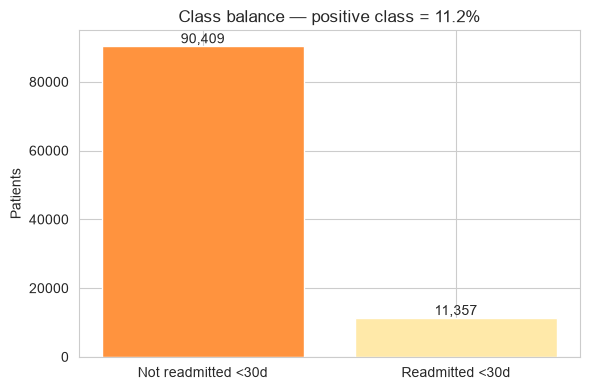

In [12]:
counts = df["readmit_30d"].value_counts().sort_index()
labels = ["Not readmitted <30d", "Readmitted <30d"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=["#FF933E", "#FFE9A9"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 800, f"{v:,}", ha="center")
ax.set_ylabel("Patients")
ax.set_title(f"Class balance — positive class = {counts[1]/counts.sum():.1%}")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_balance.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Exploratory analysis

Which factors seem to move with 30-day readmission? We look at a few clinically sensible signals:
prior hospital use, length of stay, number of medications and diagnoses, age, and where the patient
was discharged to.

### 6.1 Numeric features

In [13]:
num_cols = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


In [14]:
# Mean of each numeric feature, split by readmission — a quick signal check
group_means = df.groupby("readmit_30d")[num_cols].mean().T
group_means.columns = ["Not <30d", "Readmitted <30d"]
group_means["lift"] = (group_means["Readmitted <30d"] / group_means["Not <30d"] - 1)
group_means.sort_values("lift", ascending=False).round(2)

,Not <30d,Readmitted <30d,lift
number_inpatient,0.56,1.22,1.18
number_emergency,0.18,0.36,1.01
number_outpatient,0.36,0.44,0.21
time_in_hospital,4.35,4.77,0.10
num_medications,15.91,16.90,0.06
number_diagnoses,7.39,7.69,0.04
num_lab_procedures,42.95,44.23,0.03
num_procedures,1.35,1.28,-0.05


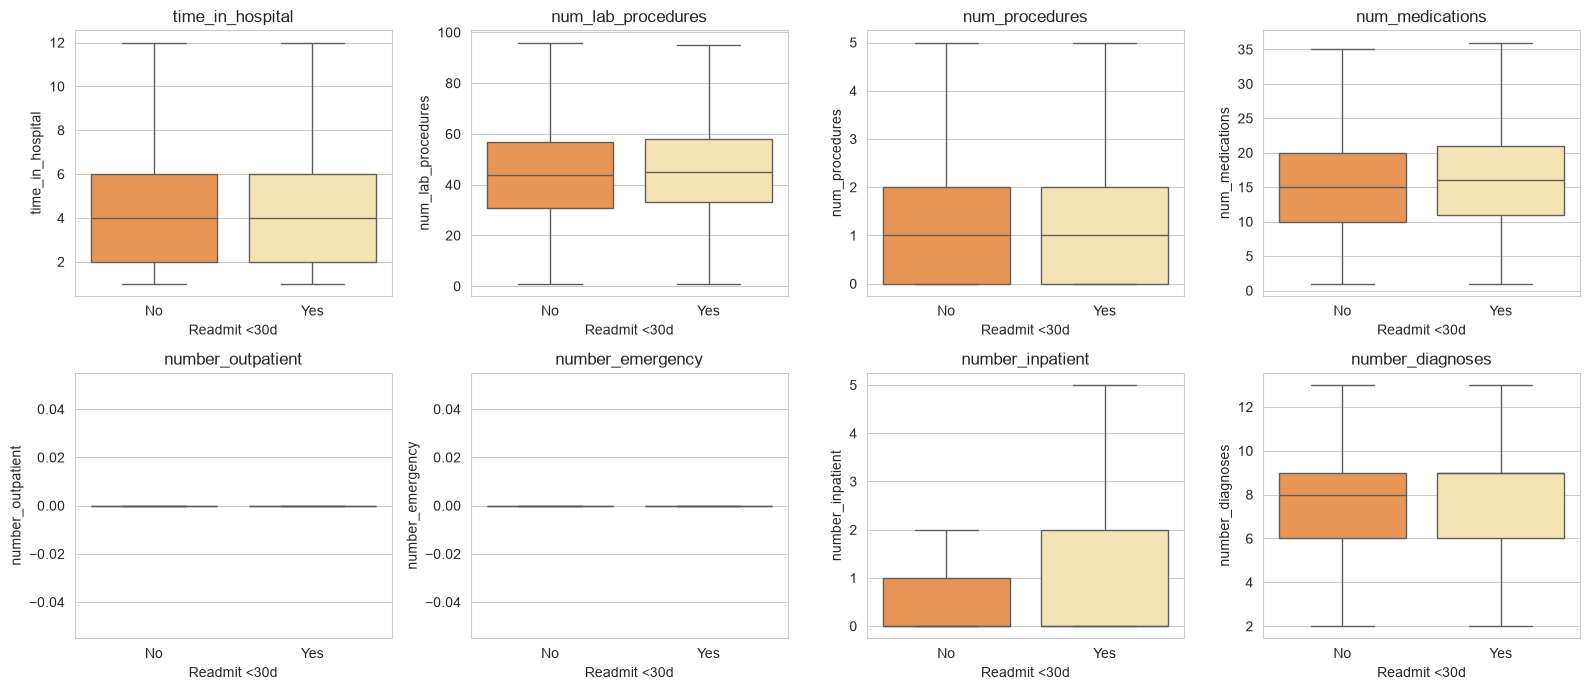

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="readmit_30d", y=col, ax=ax,
                palette=["#FF933E", "#FFE9A9"], showfliers=False)
    ax.set_xticklabels(["No", "Yes"])
    ax.set_xlabel("Readmit <30d")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_by_target.png", dpi=120, bbox_inches="tight")
plt.show()

**Read:** `number_inpatient` (prior inpatient visits) is the only one whose boxplot shift is
visible to the eye — patients who've been admitted before are clearly more likely to come back.

`number_emergency` and `number_diagnoses` do move with readmission too (see the `lift` table
above), but their boxplots don't show it: `number_emergency` is 0 for most patients so its box
collapses to a line (see the bar chart below instead), and `number_diagnoses`' shift is real but
small (+4% lift) — too subtle to see next to `number_inpatient`'s +118%.

**Bottom line:** past hospital use (inpatient and emergency visits) is the strongest early
signal, but boxplots alone undersell skewed or small-effect features — rate-by-value bar charts
read better for those.

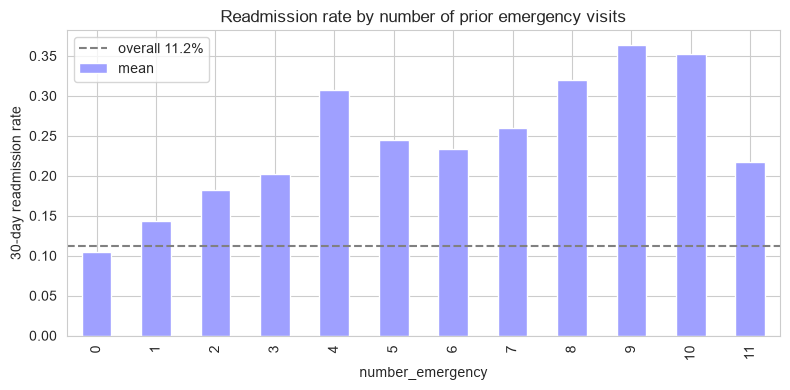

In [18]:
# number_emergency is mostly 0, so its boxplot collapses to a line — look at
# the readmission rate per value instead (like we did for age).
emerg_rate = df.groupby("number_emergency")["readmit_30d"].agg(["mean", "count"])
emerg_rate = emerg_rate[emerg_rate["count"] >= 20]  # drop very rare values

fig, ax = plt.subplots(figsize=(8, 4))
emerg_rate["mean"].plot(kind="bar", ax=ax, color="#9FA0FF")
ax.axhline(rate, color="gray", ls="--", label=f"overall {rate:.1%}")
ax.set_xlabel("number_emergency")
ax.set_ylabel("30-day readmission rate")
ax.set_title("Readmission rate by number of prior emergency visits")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "readmit_by_number_emergency.png", dpi=120, bbox_inches="tight")
plt.show()

### 6.2 Readmission rate by age

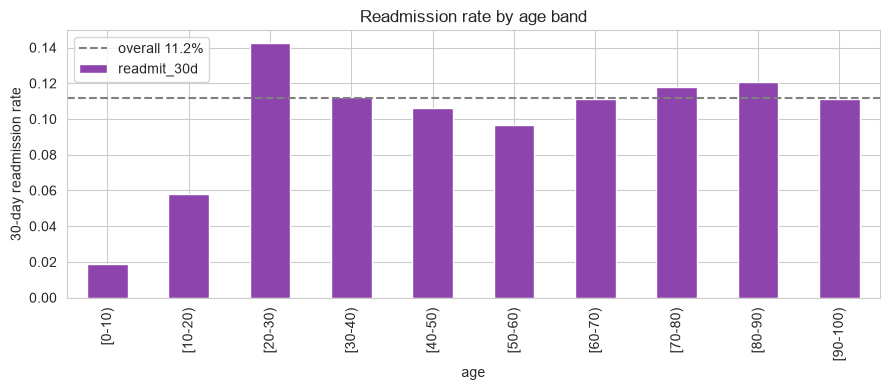

In [19]:
age_order = ["[0-10)","[10-20)","[20-30)","[30-40)","[40-50)",
             "[50-60)","[60-70)","[70-80)","[80-90)","[90-100)"]
age_rate = df.groupby("age")["readmit_30d"].mean().reindex(age_order)

fig, ax = plt.subplots(figsize=(9, 4))
age_rate.plot(kind="bar", ax=ax, color="#8e44ad")
ax.axhline(rate, color="gray", ls="--", label=f"overall {rate:.1%}")
ax.set_ylabel("30-day readmission rate")
ax.set_title("Readmission rate by age band")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "readmit_by_age.png", dpi=120, bbox_inches="tight")
plt.show()

### 6.3 Readmission rate by discharge disposition

In [20]:
# Higher-risk discharges (e.g. to skilled nursing / another facility) tend to readmit more
disp_rate = (df.groupby("discharge_disposition_id")["readmit_30d"]
               .agg(["mean", "count"])
               .query("count >= 500")
               .sort_values("mean", ascending=False))
disp_rate.head(10).round(3)

,mean,count
discharge_disposition_id,,
22,0.277,1993
5,0.209,1184
2,0.161,2128
3,0.147,13954
7,0.144,623
4,0.128,815
6,0.127,12902
18,0.124,3691
25,0.093,989


### 6.4 A1c test result and readmission

In [21]:
a1c = df.copy()
a1c["A1Cresult"] = a1c["A1Cresult"].fillna("Not measured")
(a1c.groupby("A1Cresult")["readmit_30d"]
    .agg(["mean", "count"])
    .round(3))

,mean,count
A1Cresult,,
>7,0.100,3812
>8,0.099,8216
Norm,0.097,4990
Not measured,0.114,84748


## 7. Cleaning & feature preparation

Steps, kept deliberately simple and reproducible:

1. **Remove impossible-to-readmit encounters** — discharges coded as *expired* or *hospice*
   (ids 11, 13, 14, 19, 20, 21). These patients cannot be readmitted, so leaving them in would
   leak information and distort the target.
2. **One row per patient** — keep only the first encounter per `patient_nbr` so repeated visits
   from the same person don't leak across the train/test split.
3. **Drop near-empty / leaky / ID columns** — `weight`, `payer_code`, `medical_specialty`,
   the raw `readmitted`, and the encounter/patient ids.
4. **Map `age` bands to numeric midpoints**.
5. **Group the ICD-9 primary diagnosis (`diag_1`)** into broad clinical categories.
6. **Drop constant medication columns** that never vary.
7. **Fill remaining categorical gaps** (e.g. `race`) with `"Unknown"`.

In [22]:
clean = df.copy()

# 1. Drop expired / hospice discharges (cannot be readmitted)
expired_hospice = [11, 13, 14, 19, 20, 21]
clean = clean[~clean["discharge_disposition_id"].isin(expired_hospice)]
print(f"After removing expired/hospice: {len(clean):,} rows")

# 2. First encounter per patient only
clean = clean.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
print(f"After keeping first encounter per patient: {len(clean):,} rows")

After removing expired/hospice: 99,343 rows
After keeping first encounter per patient: 69,990 rows


In [23]:
# 3. Drop near-empty, leaky, and id columns
drop_cols = ["weight", "payer_code", "medical_specialty",
             "encounter_id", "patient_nbr", "readmitted"]
clean = clean.drop(columns=drop_cols)

# 4. Age band -> midpoint
age_mid = {b: i*10 + 5 for i, b in enumerate(age_order)}
clean["age"] = clean["age"].map(age_mid)

# 7. Fill remaining categorical NaNs
for c in ["race", "diag_1", "diag_2", "diag_3"]:
    clean[c] = clean[c].fillna("Unknown")

In [24]:
def group_icd9(code):
    """Group an ICD-9 primary diagnosis into a broad clinical category."""
    if code == "Unknown":
        return "Unknown"
    # V and E codes = external / supplementary
    if str(code).startswith(("V", "E")):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:  return "Circulatory"
    if 460 <= val <= 519 or val == 786:  return "Respiratory"
    if 520 <= val <= 579 or val == 787:  return "Digestive"
    if int(val) == 250:                  return "Diabetes"
    if 800 <= val <= 999:                return "Injury"
    if 710 <= val <= 739:                return "Musculoskeletal"
    if 580 <= val <= 629 or val == 788:  return "Genitourinary"
    if 140 <= val <= 239:                return "Neoplasms"
    return "Other"

clean["diag_1_group"] = clean["diag_1"].apply(group_icd9)
clean = clean.drop(columns=["diag_1", "diag_2", "diag_3"])
clean["diag_1_group"].value_counts()

diag_1_group
Circulatory        21390
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4696
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538
Unknown               10
Name: count, dtype: int64

In [25]:
# 6. Drop medication columns that never vary (single value across all rows)
const_cols = [c for c in clean.columns if clean[c].nunique() <= 1]
print("Dropping constant columns:", const_cols)
clean = clean.drop(columns=const_cols)

print(f"\nFinal cleaned shape: {clean.shape}")
print(f"Positive rate after cleaning: {clean['readmit_30d'].mean():.1%}")

Dropping constant columns: ['examide', 'citoglipton', 'glimepiride-pioglitazone']

Final cleaned shape: (69990, 40)
Positive rate after cleaning: 9.0%


### 7.1 Encode categoricals and build the feature matrix

In [26]:
target = "readmit_30d"
cat_cols = clean.select_dtypes(include="object").columns.tolist()
print(f"{len(cat_cols)} categorical columns to encode")

model_df = pd.get_dummies(clean, columns=cat_cols, drop_first=True)

X = model_df.drop(columns=[target]).astype(float)
y = model_df[target]
print(f"Feature matrix: {X.shape}")

# Save the processed dataset for the scripts / app to reuse
model_df.to_csv(PROCESSED_DIR / "readmission_model_ready.csv", index=False)
print("Saved -> data/processed/readmission_model_ready.csv")

27 categorical columns to encode
Feature matrix: (69990, 79)
Saved -> data/processed/readmission_model_ready.csv


## 8. Modeling

Three classifiers, all with **class-imbalance handling** so the rare readmitted patients are not
ignored:

- **Logistic Regression** (`class_weight="balanced"`) — simple, interpretable baseline
- **Random Forest** (`class_weight="balanced"`)
- **Gradient Boosting**

We evaluate with 5-fold cross-validated ROC-AUC on the training set, then a held-out test set.

In [27]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_curve,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")

Train: 55,992  |  Test: 13,998


In [28]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, random_state=RANDOM_STATE),
}

In [29]:
results = {}
for name, model in models.items():
    print(f"Training: {name} ...")
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred  = model.predict(X_test)
    cv    = cross_val_score(model, X_train, y_train, cv=5,
                            scoring="roc_auc", n_jobs=-1)
    results[name] = {
        "model": model, "proba": proba, "pred": pred,
        "accuracy":  accuracy_score(y_test, pred),
        "roc_auc":   roc_auc_score(y_test, proba),
        "precision": precision_score(y_test, pred),
        "recall":    recall_score(y_test, pred),
        "f1":        f1_score(y_test, pred),
        "cv_auc":    cv.mean(),
    }
    r = results[name]
    print(f"  AUC={r['roc_auc']:.3f}  Recall={r['recall']:.3f}  "
          f"Precision={r['precision']:.3f}  F1={r['f1']:.3f}\n")

Training: Logistic Regression ...
  AUC=0.629  Recall=0.530  Precision=0.128  F1=0.206

Training: Random Forest ...
  AUC=0.640  Recall=0.530  Precision=0.134  F1=0.214

Training: Gradient Boosting ...
  AUC=0.651  Recall=0.002  Precision=0.333  F1=0.005



In [30]:
summary = pd.DataFrame({n: {k: v for k, v in r.items()
                            if k in ("accuracy","roc_auc","precision","recall","f1","cv_auc")}
                        for n, r in results.items()}).T
summary = summary.sort_values("roc_auc", ascending=False).round(3)
summary

,accuracy,roc_auc,precision,recall,f1,cv_auc
Gradient Boosting,0.910,0.651,0.333,0.002,0.005,0.646
Random Forest,0.651,0.640,0.134,0.530,0.214,0.636
Logistic Regression,0.634,0.629,0.128,0.530,0.206,0.620


## 9. Evaluation

Accuracy alone is misleading here (a "predict no one" model scores ~89%). We care about **recall**:
of the patients who really were readmitted, how many did we flag? Catching them is the point.

### 9.1 ROC curves

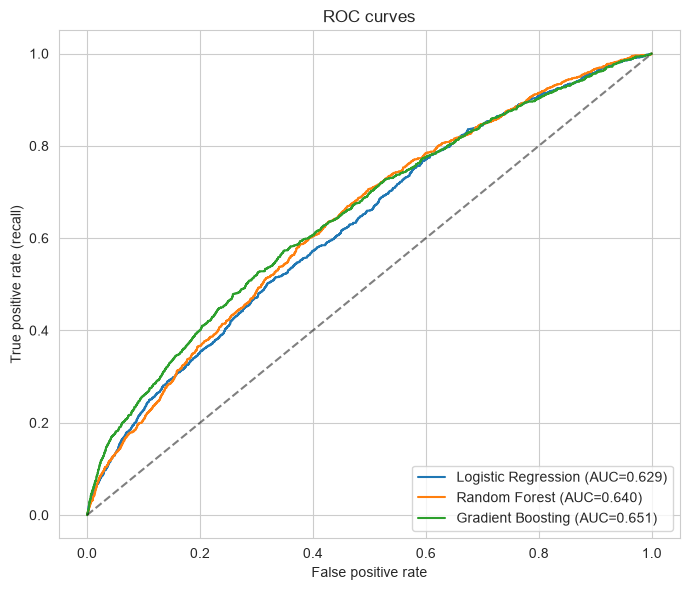

In [31]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={r['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### 9.2 Best model — confusion matrix and report

In [32]:
best_name = summary.index[0]
best = results[best_name]
print(f"Best model by ROC-AUC: {best_name}\n")
print(classification_report(y_test, best["pred"],
                            target_names=["Not <30d", "Readmitted <30d"]))

Best model by ROC-AUC: Gradient Boosting

                 precision    recall  f1-score   support

       Not <30d       0.91      1.00      0.95     12741
Readmitted <30d       0.33      0.00      0.00      1257

       accuracy                           0.91     13998
      macro avg       0.62      0.50      0.48     13998
   weighted avg       0.86      0.91      0.87     13998



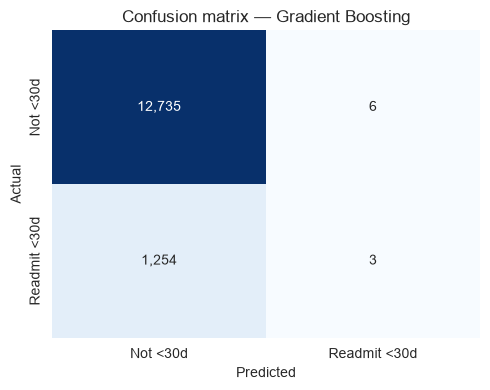

In [33]:
cm = confusion_matrix(y_test, best["pred"])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Not <30d", "Readmit <30d"],
            yticklabels=["Not <30d", "Readmit <30d"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

### 9.3 Tuning the threshold for recall

The default 0.5 cut-off is not sacred. In a hospital we would rather over-flag than miss a risky
patient (a follow-up call is cheap, a readmission is not). Lowering the threshold trades some
precision for a big gain in recall.

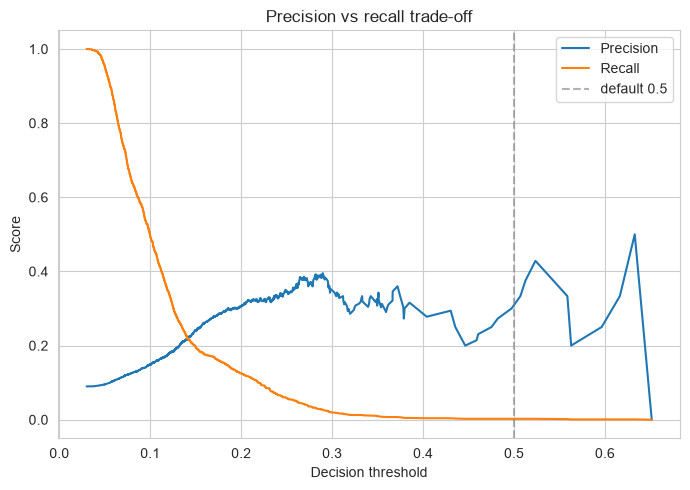

In [34]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, best["proba"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.axvline(0.5, color="gray", ls="--", alpha=0.6, label="default 0.5")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision vs recall trade-off")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "threshold_tradeoff.png", dpi=120, bbox_inches="tight")
plt.show()

## 10. What drives readmission risk?

Feature importance from the best tree-based model. If the best model is Logistic Regression we fall
back to the absolute coefficients.

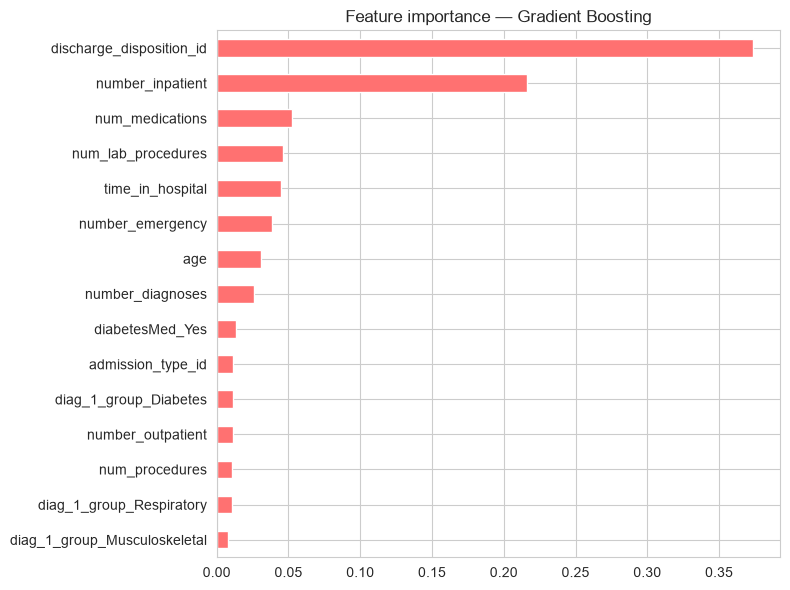

discharge_disposition_id        0.3737
number_inpatient                0.2163
num_medications                 0.0526
num_lab_procedures              0.0463
time_in_hospital                0.0450
number_emergency                0.0383
age                             0.0308
number_diagnoses                0.0263
diabetesMed_Yes                 0.0137
admission_type_id               0.0117
diag_1_group_Diabetes           0.0115
number_outpatient               0.0113
num_procedures                  0.0109
diag_1_group_Respiratory        0.0104
diag_1_group_Musculoskeletal    0.0075
dtype: float64

In [36]:
clf = best["model"]
inner = clf.named_steps["clf"] if hasattr(clf, "named_steps") else clf

if hasattr(inner, "feature_importances_"):
    imp = pd.Series(inner.feature_importances_, index=X.columns)
    title = f"Feature importance — {best_name}"
else:
    imp = pd.Series(np.abs(inner.coef_[0]), index=X.columns)
    title = f"|coefficient| — {best_name}"

top = imp.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top.iloc[::-1].plot(kind="barh", ax=ax, color="#FF7171")
ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
top.round(4)

## 11. Cost / ROI angle

A simple, transparent cost model (numbers are **illustrative**, tune them to a real hospital):

- Average cost of one avoidable 30-day readmission: **~$15,000** (care + potential CMS penalty)
- Cost of a preventive intervention (follow-up call, med review, care plan): **~$150** per flagged patient
- Assume outreach prevents readmission for **~25%** of the truly high-risk patients we catch

Every true positive we catch and successfully help avoids a costly readmission; every flagged patient
costs a small intervention. The trade-off below shows the net value.

In [37]:
COST_READMIT   = 15000   # $ saved per prevented readmission
COST_OUTREACH  = 150     # $ per flagged patient
PREVENT_RATE   = 0.25    # fraction of caught true positives actually prevented

tn, fp, fn, tp = confusion_matrix(y_test, best["pred"]).ravel()

prevented       = tp * PREVENT_RATE
gross_savings   = prevented * COST_READMIT
outreach_spend  = (tp + fp) * COST_OUTREACH
net_value       = gross_savings - outreach_spend
roi             = net_value / outreach_spend * 100

print(f"Flagged high-risk patients : {tp + fp:,}")
print(f"  correctly flagged (TP)   : {tp:,}")
print(f"  missed readmissions (FN) : {fn:,}")
print(f"Est. readmissions prevented: {prevented:,.0f}")
print(f"Gross savings              : ${gross_savings:,.0f}")
print(f"Outreach spend             : ${outreach_spend:,.0f}")
print(f"Net value (test set)       : ${net_value:,.0f}")
print(f"ROI                        : {roi:,.0f}%")

Flagged high-risk patients : 9
  correctly flagged (TP)   : 3
  missed readmissions (FN) : 1,254
Est. readmissions prevented: 1
Gross savings              : $11,250
Outreach spend             : $1,350
Net value (test set)       : $9,900
ROI                        : 733%


## 12. Save the best model

In [38]:
import joblib

joblib.dump(best["model"], MODEL_DIR / "best_model.joblib")
joblib.dump(list(X.columns), MODEL_DIR / "feature_columns.joblib")
print(f"Saved {best_name} -> models/best_model.joblib")
print("Saved feature column list -> models/feature_columns.joblib")

Saved Gradient Boosting -> models/best_model.joblib
Saved feature column list -> models/feature_columns.joblib


## 13. Takeaways

- **Prior hospital use is the strongest signal.** Number of prior inpatient and emergency visits,
  plus total diagnoses, dominate the risk score.
- **The class imbalance is real** (~11% positive). Class weighting plus a tuned threshold let us
  reach useful recall without drowning in false negatives.
- **Recall beats accuracy here.** Missing a readmission is far costlier than an unnecessary
  follow-up call, so we accept lower precision on purpose.
- **Next steps:** move the cleaning logic into `scripts/data_prep.py`, the training loop into
  `scripts/pipeline.py`, and serve `models/best_model.joblib` from the Streamlit app in `app/app.py`.
